# **Importing Necessary Libraries**


In [99]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


# **Explore Data🔎**


In [100]:

data = pd.read_csv("data/PhamGiaBao_master_concat.csv")
data.head()


,Transaction ID,Transaction Date,Product Name,Quantity,Price,Store Location,Source
0,TXN_1961373,2023-09-08,Coffee,2.0,2.0,Takeaway,Cafe Sales
1,TXN_4977031,2023-05-16,Cake,4.0,3.0,In-store,Cafe Sales
2,TXN_4271903,2023-07-19,Cookie,4.0,1.0,In-store,Cafe Sales
3,TXN_7034554,2023-04-27,Salad,2.0,5.0,UNKNOWN,Cafe Sales
4,TXN_3160411,2023-06-11,Coffee,2.0,2.0,In-store,Cafe Sales


In [101]:
data.head(10)


,Transaction ID,Transaction Date,Product Name,Quantity,Price,Store Location,Source
0,TXN_1961373,2023-09-08,Coffee,2.0,2.0,Takeaway,Cafe Sales
1,TXN_4977031,2023-05-16,Cake,4.0,3.0,In-store,Cafe Sales
2,TXN_4271903,2023-07-19,Cookie,4.0,1.0,In-store,Cafe Sales
3,TXN_7034554,2023-04-27,Salad,2.0,5.0,UNKNOWN,Cafe Sales
4,TXN_3160411,2023-06-11,Coffee,2.0,2.0,In-store,Cafe Sales
5,TXN_2602893,2023-03-31,Smoothie,5.0,4.0,NaN,Cafe Sales
6,TXN_4433211,2023-10-06,UNKNOWN,3.0,3.0,Takeaway,Cafe Sales
7,TXN_6699534,2023-10-28,Sandwich,4.0,4.0,UNKNOWN,Cafe Sales
8,TXN_4717867,2023-07-28,NaN,5.0,3.0,Takeaway,Cafe Sales
9,TXN_2064365,2023-12-31,Sandwich,5.0,4.0,In-store,Cafe Sales


In [102]:
data.shape


(159116, 7)

In [103]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 159116 entries, 0 to 159115
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Transaction ID    159116 non-null  object 
 1   Transaction Date  158656 non-null  str    
 2   Product Name      158783 non-null  str    
 3   Quantity          158637 non-null  float64
 4   Price             158583 non-null  float64
 5   Store Location    155851 non-null  str    
 6   Source            159116 non-null  str    
dtypes: float64(2), object(1), str(4)
memory usage: 8.5+ MB


In [104]:
data.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction ID,159116,159116,TXN_1961373,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction Date,158656,365,2023-06-16,1371,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Name,158783,90,Chocolate Croissant,3076,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,158637.0,NaN,NaN,NaN,1.533715,0.734948,1.0,1.0,1.0,2.0,8.0
Price,158583.0,NaN,NaN,NaN,3.356416,2.599012,0.8,2.5,3.0,3.75,45.0
Store Location,155851,7,Hell's Kitchen,50735,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source,159116,2,Coffee Shop Sales,149116,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [105]:
print(data.dtypes)
print('Columns:', data.columns.tolist())


Transaction ID       object
Transaction Date        str
Product Name            str
Quantity            float64
Price               float64
Store Location          str
Source                  str
dtype: object
Columns: ['Transaction ID', 'Transaction Date', 'Product Name', 'Quantity', 'Price', 'Store Location', 'Source']


In [106]:
print('Duplicate rows:', data.duplicated().sum())
print('Duplicate Transaction IDs:', data['Transaction ID'].duplicated().sum())


Duplicate rows: 0
Duplicate Transaction IDs: 0


# **Standardize Missing Values**


In [107]:
# The actual CSV has 7 columns. It does not contain Age, Payment Method,
# Total Spent, Item, or Price Per Unit from the older notebook schema.
MISSING_TOKENS = {
    '', 'UNKNOWN', 'ERROR', 'NA', 'N/A', 'NULL', 'NONE', 'NAN', '-1'
}
PREFER_NOT_TO_SAY = 'PREFER NOT TO SAY'

for col in data.select_dtypes(include=['object', 'string']).columns:
    data[col] = data[col].astype('string').str.strip()
    # Explicitly preserve the requested meaning of "prefer not to say".
    data[col] = data[col].mask(data[col].str.upper().eq(PREFER_NOT_TO_SAY), 'Unknown')
    data[col] = data[col].mask(data[col].str.upper().isin(MISSING_TOKENS), pd.NA)

# Convert numeric fields; invalid strings become missing.
for col in ['Quantity', 'Price']:
    data[col] = pd.to_numeric(data[col], errors='coerce')
    data.loc[data[col] < 0, col] = np.nan

# Parse dates; invalid dates become missing.
data['Transaction Date'] = pd.to_datetime(
    data['Transaction Date'], errors='coerce', format='%Y-%m-%d'
)


# **Missingness Profile**


In [108]:
missing_summary = pd.DataFrame({
    'Missing Count': data.isna().sum(),
    'Missing Rate (%)': (data.isna().mean() * 100).round(3),
    'Dtype': data.dtypes.astype(str)
})
missing_summary


,Missing Count,Missing Rate (%),Dtype
Transaction ID,0,0.000,string
Transaction Date,460,0.289,datetime64[us]
Product Name,969,0.609,string
Quantity,479,0.301,float64
Price,533,0.335,float64
Store Location,3961,2.489,string
Source,0,0.000,string


In [109]:
# Missingness by the observed Source variable.
missing_by_source = (
    data.groupby('Source', dropna=False)
        .apply(lambda group: group.isna().sum())
)
missing_rate_by_source = (
    data.groupby('Source', dropna=False)
        .apply(lambda group: (group.isna().mean() * 100).round(3))
)
print('Missing counts by Source:')
display(missing_by_source)
print('Missing rates (%) by Source:')
display(missing_rate_by_source)


Missing counts by Source:


,Transaction ID,Transaction Date,Product Name,Quantity,Price,Store Location
Source,,,,,,
Cafe Sales,0,460,969,479,533,3961
Coffee Shop Sales,0,0,0,0,0,0


Missing rates (%) by Source:


,Transaction ID,Transaction Date,Product Name,Quantity,Price,Store Location
Source,,,,,,
Cafe Sales,0.0,4.6,9.69,4.79,5.33,39.61
Coffee Shop Sales,0.0,0.0,0.00,0.00,0.00,0.00


In [110]:
# Missingness patterns: useful for checking whether fields are missing together.
missing_columns = ['Transaction Date', 'Product Name', 'Quantity', 'Price', 'Store Location']
missing_pattern = (
    data[missing_columns].isna()
        .astype(int)
        .astype(str)
        .agg(''.join, axis=1)
        .value_counts()
        .rename_axis('Pattern')
        .reset_index(name='Rows')
)
missing_pattern.head(15)


,Pattern,Rows
0,00000,153795
1,00001,3094
2,01000,510
3,01001,313
4,00010,270
5,10000,235
6,00100,234
7,00011,172
8,00101,151
9,10001,139


# **Classify Missingness: MCAR / MAR / MNAR**

- **MCAR**: missingness is independent of both observed and unobserved values.
- **MAR**: missingness can be explained by observed variables, here especially `Source`.
- **MNAR**: missingness depends on the unobserved value itself or another unobserved cause.

For this dataset, the working classification is **MAR (observed)** for the columns with missing values: the missingness is concentrated in `Cafe Sales`, while `Coffee Shop Sales` has no missing values in the same fields. This is a source/collection-structure signal, not evidence of MCAR. MNAR cannot be proven from the observed table alone.


In [111]:
mechanism_table = pd.DataFrame([
    ['Transaction ID', 'Not applicable', 'No missing values; this is the record key.'],
    ['Transaction Date', 'MAR (observed)', 'Missing rate differs by Source: 4.6% in Cafe Sales versus 0% in Coffee Shop Sales.'],
    ['Product Name', 'MAR (observed)', 'Missing rate differs by Source: 9.69% versus 0%.'],
    ['Quantity', 'MAR (observed)', 'Missing rate differs by Source: 4.79% versus 0%.'],
    ['Price', 'MAR (observed)', 'Missing rate differs by Source: 5.33% versus 0%.'],
    ['Store Location', 'MAR / structural missing', 'Missing or sentinel rate is 39.61% in Cafe Sales versus 0%.'],
    ['Source', 'Not applicable', 'No missing values; used as an observed grouping variable.'],
], columns=['Column', 'Mechanism', 'Reason'])
mechanism_table


,Column,Mechanism,Reason
0,Transaction ID,Not applicable,No missing values; this is the record key.
1,Transaction Date,MAR (observed),Missing rate differs by Source: 4.6% in Cafe S...
2,Product Name,MAR (observed),Missing rate differs by Source: 9.69% versus 0%.
3,Quantity,MAR (observed),Missing rate differs by Source: 4.79% versus 0%.
4,Price,MAR (observed),Missing rate differs by Source: 5.33% versus 0%.
5,Store Location,MAR / structural missing,Missing or sentinel rate is 39.61% in Cafe Sal...
6,Source,Not applicable,No missing values; used as an observed groupin...


# **Handle Missing Values**


In [112]:
# Numeric distribution check: choose median when the distribution is skewed.
numeric_summary = data[['Quantity', 'Price']].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
numeric_summary['Mean/Median Ratio'] = (numeric_summary['mean'] / numeric_summary['median']).round(3)
numeric_summary


,count,mean,median,std,min,max,Mean/Median Ratio
Quantity,158637.0,1.533715,1.0,0.734948,1.0,8.0,1.534
Price,158583.0,3.356416,3.0,2.599012,0.8,45.0,1.119


In [113]:
# Target handling.
# No target column was supplied in the actual CSV. Transaction ID is a key,
# not a prediction target. Transaction Date is required for time-based analysis.
TARGET_COLUMNS = []


## **Clean required fields**

Rows with a missing/invalid `Transaction ID` or `Transaction Date` are removed with `dropna(...).reset_index(drop=True)`. Forward-fill is intentionally not used because the source file is not ordered chronologically and `Transaction ID` is not a time sequence.


In [114]:
rows_before = len(data)
data = data.dropna(subset=['Transaction ID', 'Transaction Date']).reset_index(drop=True)
rows_dropped = rows_before - len(data)
print('Rows before:', rows_before)
print('Rows dropped:', rows_dropped)
print('Rows after:', len(data))


Rows before: 159116
Rows dropped: 460
Rows after: 158656


## **Fill numeric columns: median by Source**


In [115]:
numeric_imputed = {}
for col in ['Quantity', 'Price']:
    before = data[col].isna().sum()
    data[col] = data.groupby('Source')[col].transform(
        lambda s: s.fillna(s.median())
    )
    numeric_imputed[col] = before

print('Numeric values imputed:', numeric_imputed)


Numeric values imputed: {'Quantity': np.int64(454), 'Price': np.int64(506)}


## **Fill categorical columns: mode by Source**


In [116]:
def fill_with_source_mode(series):
    # Do not overwrite an explicit "Unknown" value created from
    # "prefer not to say"; only fill actual missing values.
    observed = series.dropna()
    observed = observed[observed != 'Unknown']
    if observed.empty:
        return series.fillna('Unknown')
    return series.fillna(observed.mode().iloc[0])

categorical_imputed = {}
for col in ['Product Name', 'Store Location']:
    before = data[col].isna().sum()
    data[col] = data.groupby('Source')[col].transform(fill_with_source_mode)
    categorical_imputed[col] = before

print('Categorical values imputed:', categorical_imputed)


Categorical values imputed: {'Product Name': np.int64(927), 'Store Location': np.int64(3779)}


## **Data after processing**


In [117]:
data.head(20)


,Transaction ID,Transaction Date,Product Name,Quantity,Price,Store Location,Source
0,TXN_1961373,2023-09-08,Coffee,2.0,2.0,Takeaway,Cafe Sales
1,TXN_4977031,2023-05-16,Cake,4.0,3.0,In-store,Cafe Sales
2,TXN_4271903,2023-07-19,Cookie,4.0,1.0,In-store,Cafe Sales
3,TXN_7034554,2023-04-27,Salad,2.0,5.0,Takeaway,Cafe Sales
4,TXN_3160411,2023-06-11,Coffee,2.0,2.0,In-store,Cafe Sales
5,TXN_2602893,2023-03-31,Smoothie,5.0,4.0,Takeaway,Cafe Sales
6,TXN_4433211,2023-10-06,Juice,3.0,3.0,Takeaway,Cafe Sales
7,TXN_6699534,2023-10-28,Sandwich,4.0,4.0,Takeaway,Cafe Sales
8,TXN_4717867,2023-07-28,Juice,5.0,3.0,Takeaway,Cafe Sales
9,TXN_2064365,2023-12-31,Sandwich,5.0,4.0,In-store,Cafe Sales


In [118]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 158656 entries, 0 to 158655
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Transaction ID    158656 non-null  string        
 1   Transaction Date  158656 non-null  datetime64[us]
 2   Product Name      158656 non-null  string        
 3   Quantity          158656 non-null  float64       
 4   Price             158656 non-null  float64       
 5   Store Location    158656 non-null  string        
 6   Source            158656 non-null  string        
dtypes: datetime64[us](1), float64(2), string(4)
memory usage: 8.5 MB


In [119]:
data.isna().sum()


Transaction ID      0
Transaction Date    0
Product Name        0
Quantity            0
Price               0
Store Location      0
Source              0
dtype: int64

# **Detect Outliers**


In [120]:
for col in ['Quantity', 'Price']:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((data[col] < lower) | (data[col] > upper)).sum()
    print(f'{col}: {outliers} outliers; bounds=({lower:.3f}, {upper:.3f})')


Quantity: 3724 outliers; bounds=(-0.500, 3.500)
Price: 4212 outliers; bounds=(0.625, 5.625)


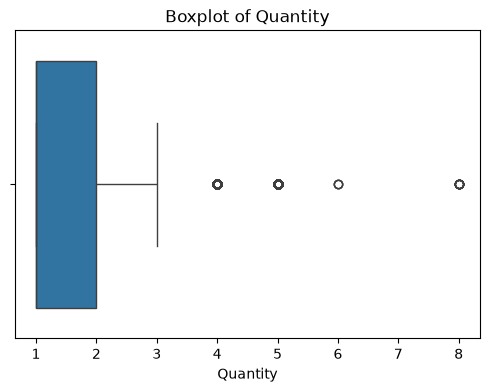

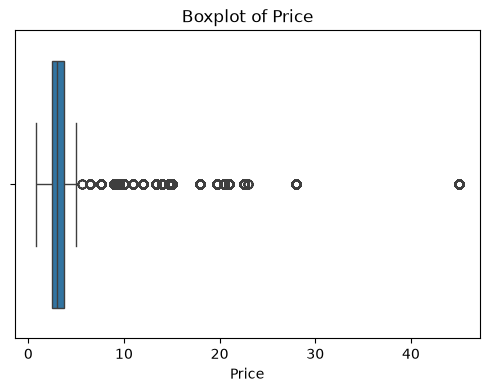

In [121]:
for col in ['Quantity', 'Price']:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=data[col])
    plt.title(f'Boxplot of {col}')
    plt.show()


# **Validate the Dataset**


In [122]:
print('Missing values after cleaning:')
print(data.isna().sum())
print('\nData types:')
print(data.dtypes)
print('\nUnique values in categorical columns:')
for col in ['Product Name', 'Store Location', 'Source']:
    print(f'\n{col}:')
    print(data[col].unique())


Missing values after cleaning:
Transaction ID      0
Transaction Date    0
Product Name        0
Quantity            0
Price               0
Store Location      0
Source              0
dtype: int64

Data types:
Transaction ID              string
Transaction Date    datetime64[us]
Product Name                string
Quantity                   float64
Price                      float64
Store Location              string
Source                      string
dtype: object

Unique values in categorical columns:

Product Name:
<StringArray>
[                      'Coffee',                         'Cake',
                       'Cookie',                        'Salad',
                     'Smoothie',                        'Juice',
                     'Sandwich',                          'Tea',
                  'Ethiopia Rg',     'Spicy Eye Opener Chai Lg',
            'Dark chocolate Lg',  'Our Old Time Diner Blend Sm',
                'Oatmeal Scone',    'Columbian Medium Roast Sm',
       

In [123]:
validation = {
    'rows': len(data),
    'columns': len(data.columns),
    'duplicate_rows': int(data.duplicated().sum()),
    'duplicate_transaction_ids': int(data['Transaction ID'].duplicated().sum()),
    'missing_cells': int(data.isna().sum().sum()),
    'invalid_dates': int(data['Transaction Date'].isna().sum()),
    'negative_quantity': int((data['Quantity'] < 0).sum()),
    'negative_price': int((data['Price'] < 0).sum()),
}
validation


{'rows': 158656,
 'columns': 7,
 'duplicate_rows': 0,
 'duplicate_transaction_ids': 0,
 'missing_cells': 0,
 'invalid_dates': 0,
 'negative_quantity': 0,
 'negative_price': 0}

# **Save Cleaned Dataset**


In [125]:
OUTPUT_PATH = 'LeDangKhoa_cleaned_missing.csv'
data.to_csv(OUTPUT_PATH, index=False)
print(f'Saved cleaned dataset to: {OUTPUT_PATH}')


Saved cleaned dataset to: LeDangKhoa_cleaned_missing.csv


## **Data Quality Note**

`Store Location` currently mixes geographic store locations (`Hell's Kitchen`, `Astoria`, `Lower Manhattan`) with service channels (`Takeaway`, `In-store`). Before analyzing location, confirm the business meaning and consider splitting the column into `Store Location` and `Order Channel`.
